### 1. Download and Prepare the Mall Customers Dataset
We will download the standard `Mall_Customers.csv` dataset to `/content/sample_data/Mall_Customers.csv` if it does not already exist, and load it into a pandas DataFrame.

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch



# Load dataset
df = pd.read_csv('/content/sample_data/Mall_Customers.csv')
display(df.head())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 2. Visualize Dendrogram
We will use `Annual Income (k$)` and `Spending Score (1-100)` for our clustering task. Let's plot the dendrogram to find the optimal number of clusters.

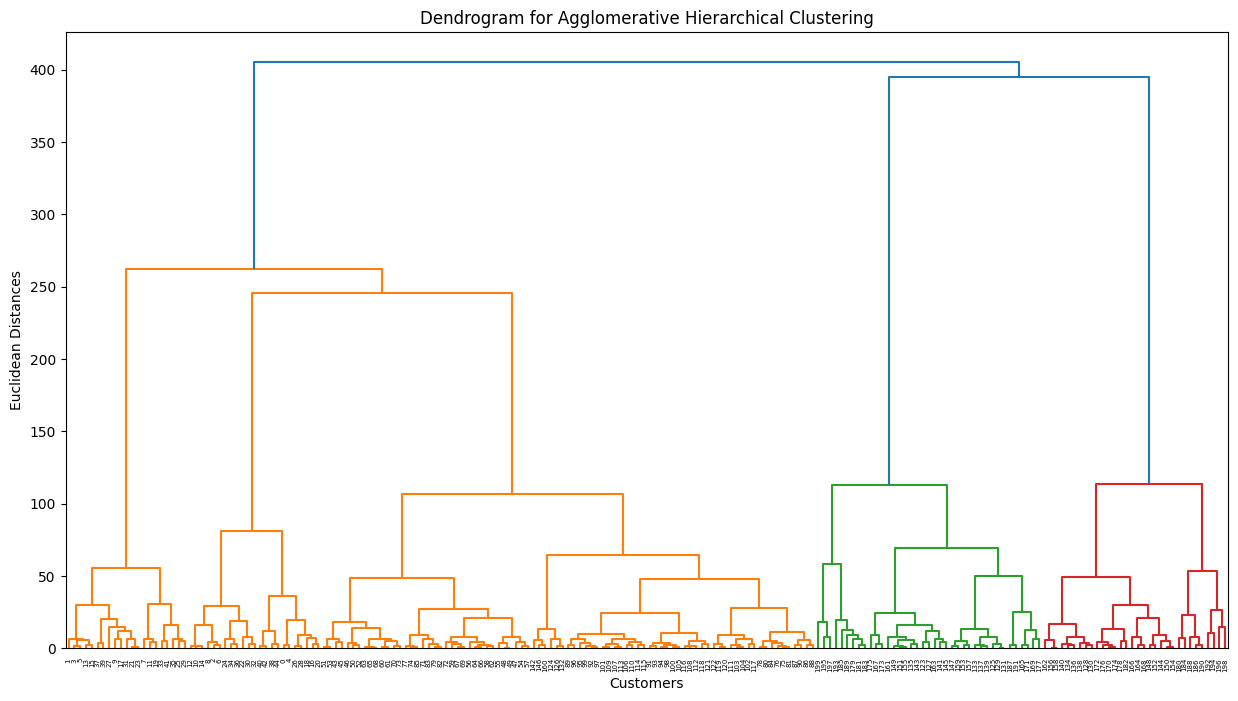

In [11]:
# Selecting features for clustering
X = df.iloc[:, [3, 4]].values

plt.figure(figsize=(15, 8))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram for Agglomerative Hierarchical Clustering')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()

### 3. Fit Agglomerative Clustering
Based on the dendrogram, 5 clusters is a suitable choice (the longest vertical distance without crossing any horizontal line).

In [12]:
# Fitting Hierarchical Clustering to the dataset
hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

# Add cluster labels to the original dataframe
df['Cluster'] = y_hc
display(df.head())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4


### 4. Visualize the Clusters
Let's plot the 5 resulting clusters of customers.

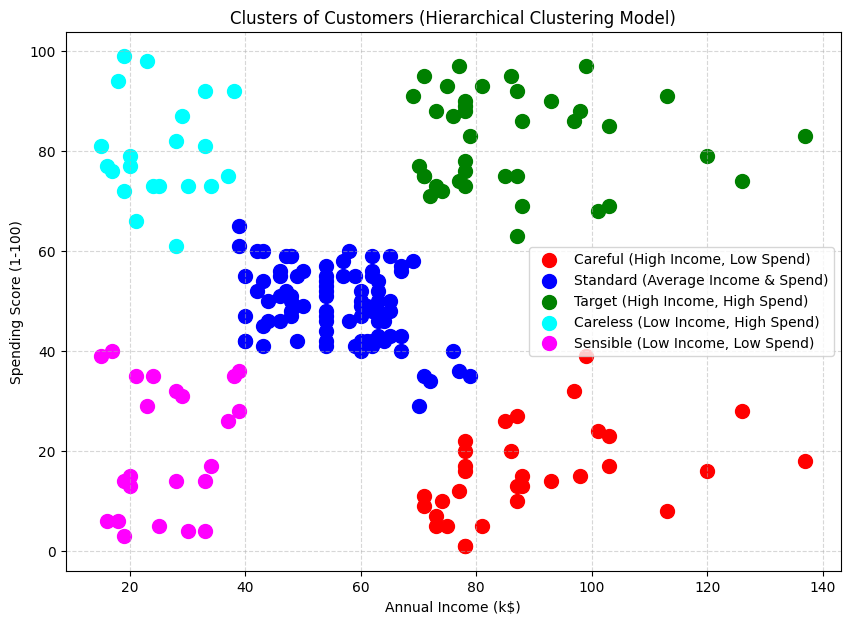

In [13]:
plt.figure(figsize=(10, 7))
plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s=100, c='red', label='Careful (High Income, Low Spend)')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s=100, c='blue', label='Standard (Average Income & Spend)')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s=100, c='green', label='Target (High Income, High Spend)')
plt.scatter(X[y_hc == 3, 0], X[y_hc == 3, 1], s=100, c='cyan', label='Careless (Low Income, High Spend)')
plt.scatter(X[y_hc == 4, 0], X[y_hc == 4, 1], s=100, c='magenta', label='Sensible (Low Income, Low Spend)')

plt.title('Clusters of Customers (Hierarchical Clustering Model)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()